# 03 · Models: regression and classification

**Goal:** understand what each model does, how to read its scores, and why the winner won.

All models were trained by `run_pipeline.py`. This notebook only **reads** the saved results, so it runs in seconds.

**Two kinds of task:**
- **Regression**: predict a *number* (vehicles next half hour, speed)
- **Classification**: predict a *label* (Free-flow / Moderate / Heavy / Severe; accident yes/no)

In [1]:
# --- setup: run this cell first ---
import sys
sys.path.insert(0, "../src")          # so we can use the project's own helpers

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils import path                # path("raw", "file.csv") -> full path to data/raw/file.csv

plt.rcParams["figure.figsize"] = (10, 4)
pd.set_option("display.width", 120)
import json
board = json.loads(path("reports", "scoreboard.json").read_text())
dl = json.loads(path("reports", "dl_result.json").read_text())
preds = pd.read_parquet(path("reports", "test_predictions.parquet"))
print("model version:", board["version"])

model version: 1.0-5bb519c5


## How the data was split

The models learned from the **past** and were tested on the **future**, never shuffled:

| Part | Dates | Used for |
|---|---|---|
| Train (70%) | 1 Jan → 16 Apr | learning, and choosing the best settings |
| Validation (10%) | 16 Apr → 1 May | sizing the ± ranges, the alert threshold |
| Test (20%) | 1 May → 31 May | the final exam, looked at **once** |

Shuffling would let a model "see" days after the ones it's tested on, and its score would look better than it really is.

## Part 1 · Regression: predicting next half hour's traffic volume

### The scores, in plain words
- **MAE**: the average miss, in vehicles
- **RMSE**: like MAE, but big misses count extra (our main score, since big rush-hour misses hurt most)
- **MAPE**: the average miss as a % of the real number

In [2]:
rows = []
for c in board["volume"]["candidates"]:
    rows.append({"model": c["model"],
                 "CV RMSE (used to choose)": round(c["cv_rmse"], 1),
                 "test RMSE": round(c["test"]["rmse"], 1),
                 "test MAE": round(c["test"]["mae"], 1),
                 "test MAPE %": round(c["test"]["mape"], 2)})
rows.append({"model": "Scratch NumPy LinReg", "test RMSE": round(board["volume"]["scratch_linreg"]["rmse"], 1)})
pd.DataFrame(rows).sort_values("test RMSE")

,model,CV RMSE (used to choose),test RMSE,test MAE,test MAPE %
3,XGBoost,60.9,58.3,40.1,9.55
2,Random Forest,63.4,58.5,39.8,9.39
1,Decision Tree,73.2,70.2,48.0,11.46
0,Linear Regression,72.0,70.4,48.9,12.63
4,Scratch NumPy LinReg,NaN,74.0,NaN,NaN


**How to read it:**
- **Linear regression** adds up one weight per feature. Simple, but traffic curves aren't straight lines.
- **Decision tree** asks yes/no questions ("was it over 490 cars 30 min ago?").
- **Random forest** averages 100 trees, each trained on a random slice of the data.
- **XGBoost** builds trees one after another, each fixing the mistakes of the ones before.

The two tree **ensembles** win by about 12 vehicles. XGBoost was picked by its **CV score**, before anyone looked at the test column.

### See the forecasts against reality

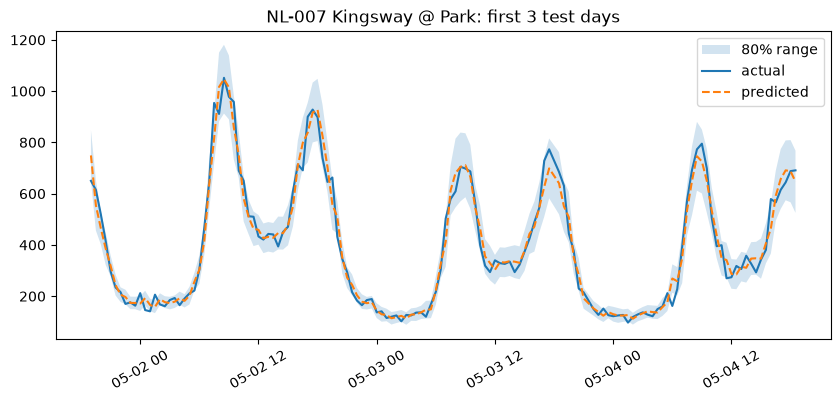

In [3]:
one_road = preds[(preds["target"] == "traffic_volume") & (preds["horizon"] == 1) & (preds["road_id"] == "NL-007")]
first_days = one_road[one_road["timestamp"] < one_road["timestamp"].min() + pd.Timedelta(days=3)]

plt.fill_between(first_days["timestamp"], first_days["lower"], first_days["upper"], alpha=0.2, label="80% range")
plt.plot(first_days["timestamp"], first_days["actual"], label="actual")
plt.plot(first_days["timestamp"], first_days["pred"], "--", label="predicted")
plt.legend(); plt.title("NL-007 Kingsway @ Park: first 3 test days"); plt.xticks(rotation=30)
plt.show()

**How to read it:** the dashed line follows the real one closely. The shaded band is the **80% range**: the real value should land inside it about 80% of the time. Check it:

In [4]:
v1 = preds[(preds["target"] == "traffic_volume") & (preds["horizon"] == 1)]
inside = ((v1["actual"] >= v1["lower"]) & (v1["actual"] <= v1["upper"])).mean()
print(f"real value inside the 80% range: {inside:.1%}")

real value inside the 80% range: 80.9%


### Where does the model struggle?

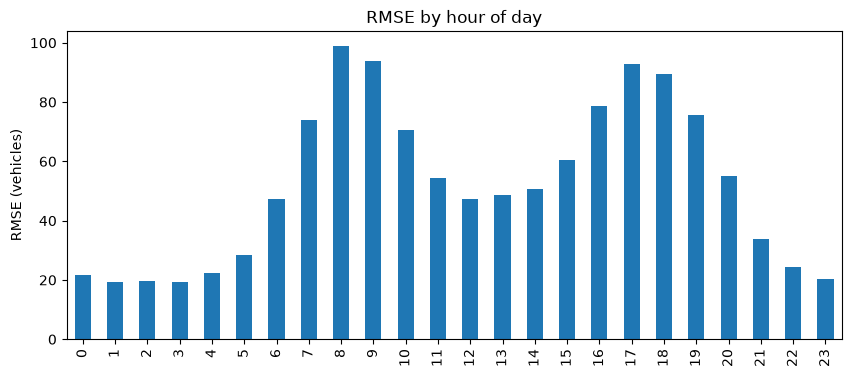

In [5]:
by_hour = pd.Series(board["volume"]["error_breakdown"]["hour"])
by_hour.index = by_hour.index.astype(int)
by_hour.sort_index().plot.bar(title="RMSE by hour of day")
plt.ylabel("RMSE (vehicles)"); plt.show()

**How to read it:** errors are biggest at rush hour (8–9 am, 5–6 pm) and tiny at night. Busy times are harder to predict, which is also why the ± range is wider at rush hour.

## Part 2 · Classification: congestion level (4 classes)

### Why not just use accuracy?
If most windows are Free-flow, a model that *always* says "Free-flow" already looks good on accuracy. **Macro-F1** scores each class separately and averages them equally, so the rare Severe class counts as much as Free-flow.

In [6]:
c = board["congestion"]["test"]
print(f"accuracy: {c['accuracy']:.3f}   macro-F1: {c['macro_f1']:.3f}")
print()
print(pd.DataFrame({"precision": c["precision"], "recall": c["recall"]}))

accuracy: 0.877   macro-F1: 0.769

           precision  recall
Free-flow      0.965   0.954
Moderate       0.811   0.838
Heavy          0.621   0.660
Severe         0.701   0.609


- **precision** for Severe: when the model says "Severe", how often is it right?
- **recall** for Severe: of all the real Severe windows, how many did it catch?

### The confusion matrix
Rows are what really happened, columns are what the model predicted. The diagonal is correct.

In [7]:
levels = ["Free-flow", "Moderate", "Heavy", "Severe"]
pd.DataFrame(c["confusion_matrix"], index=["actual " + l for l in levels], columns=["pred " + l for l in levels])

,pred Free-flow,pred Moderate,pred Heavy,pred Severe
actual Free-flow,20326,974,0,0
actual Moderate,739,7134,625,18
actual Heavy,0,682,2311,506
actual Severe,0,6,783,1230


**How to read it:** almost every mistake is between **neighbouring** levels (Heavy vs Severe, Moderate vs Heavy). Free-flow is never confused with Heavy or Severe. Mistakes sit near the boundaries, where even a human would hesitate.

## Part 3 · Classification: accident risk (rare yes/no)

Under 1% of windows have an accident. The model gives each window a **probability**, and we raise an alert when it's above a **threshold**.

In [8]:
a = board["accident"]["test"]
print(f"ROC-AUC: {a['roc_auc']:.3f}   (0.5 = coin flip, 1.0 = perfect ranking)")
print(f"real accident rate: {a['base_rate']:.2%}   average predicted risk: {a['mean_predicted_probability']:.2%}")
print(f"at the alert threshold: {a['alerts_per_1000_windows']:.0f} alerts per 1,000 windows, "
      f"catching {a['recall']:.0%} of accidents, each alert right {a['precision']:.1%} of the time")

ROC-AUC: 0.617   (0.5 = coin flip, 1.0 = perfect ranking)
real accident rate: 0.97%   average predicted risk: 0.87%
at the alert threshold: 77 alerts per 1,000 windows, catching 21% of accidents, each alert right 2.7% of the time


**How to read it:** ROC-AUC 0.62 means the model ranks risky windows above safe ones somewhat better than chance, but not reliably. Its alerts are right about **2.8 times** more often than a random guess (2.7% vs 0.97%), but most alerts are still false alarms. Every model family scored similarly, which suggests the data just doesn't contain much warning before an accident.

## Part 4 · Does a neural network do better?

In [9]:
rows = [{"model": "XGBoost (classical)", "test RMSE": round(dl["classical"]["rmse"], 2)}]
for name, v in dl["variants"].items():
    rows.append({"model": name, "test RMSE": round(v["test"]["rmse"], 2), "epochs": v["test"]["epochs_run"]})
pd.DataFrame(rows)

,model,test RMSE,epochs
0,XGBoost (classical),58.29,NaN
1,LSTM,61.86,8.0
2,BiLSTM,60.45,9.0


**How to read it:** the LSTM reads the last 8 hours as a sequence and learns its own history features. On the same test rows the better network (BiLSTM) is 3.7% worse than XGBoost and the plain LSTM 6.1% worse. Both are slower to train and harder to explain. The simpler model is the one to use. "The fancier model didn't help" is a real, useful result.

## Summary

| Task | Winner | Score |
|---|---|---|
| Volume (regression) | XGBoost | MAPE 9.55% (target ≤ 12% ✓) |
| Congestion (4 classes) | XGBoost | macro-F1 0.769 (target 0.80 ✗) |
| Accident risk (yes/no) | Logistic regression | ROC-AUC 0.617 (target 0.75 ✗) |
| Neural network vs XGBoost | XGBoost | best network 3.7% behind |